# Applying *k*-Means: World Bank Country Data

## Brief


In this notebook, we're going to use the World Bank Country Data to classify countries based on their features.

Take a look at the full data columns below:

|Variable|Full variable name|Description|
|:---|:---|:---|
|country|Country name|The full name of the country.
|female_labour|Female labour force participation rate|The percentage of females ages 15 and older that are economically active, i.e., part of the labour force|
|fertility_rate|Fertility rate|The average number of births for a woman who lives to the end of her childbearing years|
|gdp_pc|GDP per capita|Gross domestic product of a country in USD|
|unemployment_rate|Unemployment rate|The percentage of the labour force that is unemployed|

The data is from the 2018 World Bank Development Indicators, which you can take a look at [here](https://databank.worldbank.org/source/world-development-indicators#). 



## Import libraries

Update and run the cell below to import the relevant libraries

In [1]:
# load in relevant libraries

# for loading and manipulating dataframes
import pandas as pd
import numpy as np

# for various plotting functions
import matplotlib.pyplot as plt
import seaborn as sns

# to pre-process our data
from sklearn.preprocessing import StandardScaler, OneHotEncoder, RobustScaler

# to carry out k-means
from sklearn.cluster import KMeans

# to carry out DBSCAN
from sklearn.cluster import DBSCAN

# to evaluate our clustering
from sklearn.metrics import silhouette_score

## Load and explore the data
### *Load data*
Load our data `countries_workshop.csv` into a variable named `countries_df`.

In [2]:
# load the data

countries_df = pd.read_csv('data/countries_workshop.csv')
countries_df.head()

,country,female_labour,fertility_rate,gdp_pc,unemployment_rate
0,Afghanistan,21.25,4.47,568.83,11.06
1,Albania,42.19,1.62,4433.74,12.30
2,Algeria,20.13,3.02,4158.33,11.89
3,Angola,50.20,5.52,3595.11,7.00
4,Argentina,43.00,2.26,13112.40,9.22


### *Explore the data*


In [3]:
# gain overview of data
countries_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 179 entries, 0 to 178
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   country            179 non-null    str    
 1   female_labour      179 non-null    float64
 2   fertility_rate     179 non-null    float64
 3   gdp_pc             179 non-null    float64
 4   unemployment_rate  179 non-null    float64
dtypes: float64(4), str(1)
memory usage: 8.7 KB


*All data types look fine and there is no missing values*

In [4]:
# get summary stats

countries_df.describe()

,female_labour,fertility_rate,gdp_pc,unemployment_rate
count,179.00000,179.000000,179.000000,179.000000
mean,41.37257,2.683631,14273.625754,7.107207
std,9.30866,1.298382,19431.092663,5.417298
min,7.90000,0.980000,281.970000,0.110000
25%,39.11000,1.675000,2000.720000,3.525000
50%,44.23000,2.240000,5639.900000,5.370000
75%,47.65000,3.600000,16647.960000,9.155000
max,55.96000,6.910000,104261.940000,26.910000


*It appears that GDP per capita has outlier values---> Deal with outliers*

*All variables use a different scale --> Scale your data*

In [5]:
# Select numerical columns
num_cols = countries_df.select_dtypes(include='number').columns.to_list()

# Calculate IQR
Q1 = countries_df[num_cols].quantile(0.25)
Q3 = countries_df[num_cols].quantile(0.75)
IQR = Q3 - Q1

# Define outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Detect outliers
outliers = (countries_df[num_cols] < lower_bound) | (countries_df[num_cols] > upper_bound)

# Count outliers per column
outliers.sum()

female_labour        20
fertility_rate        1
gdp_pc               22
unemployment_rate    13
dtype: int64

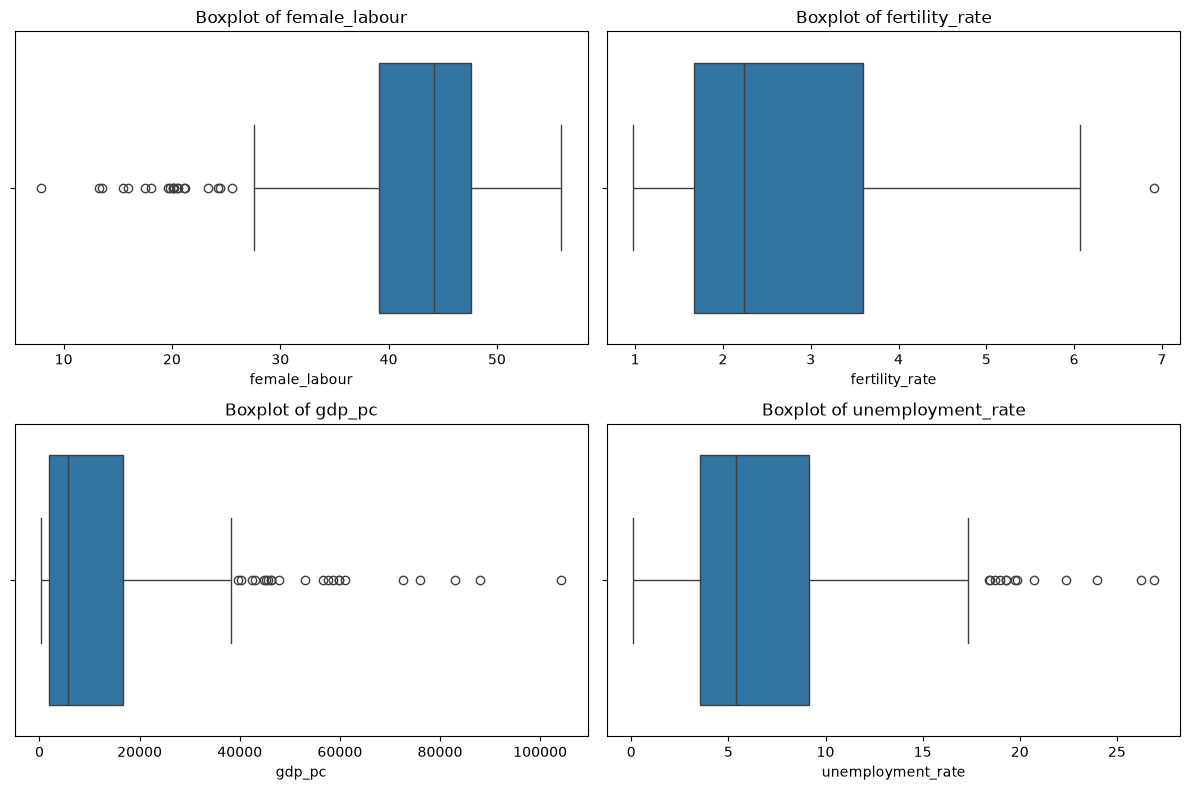

In [6]:
# Show box plot

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x=countries_df[col], ax=ax)
    ax.set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

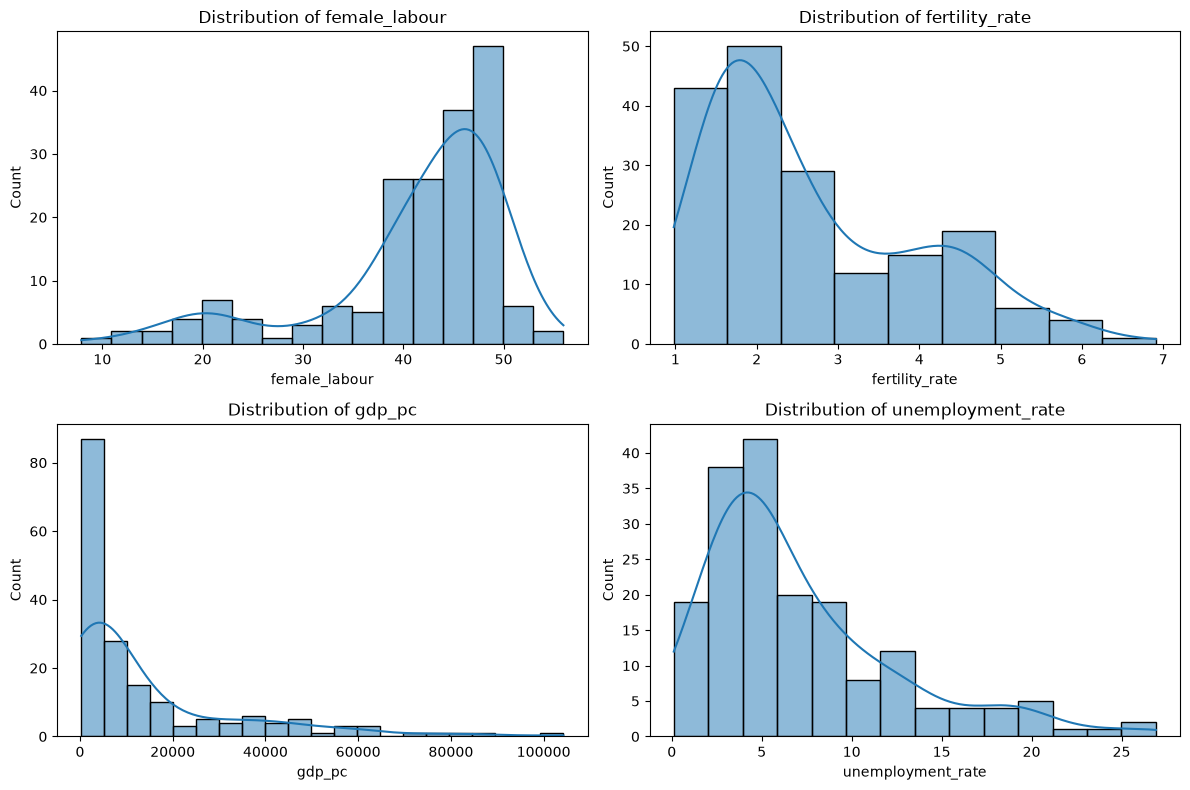

In [7]:
# Show the distribution of your features

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, num_cols):
    sns.histplot(data=countries_df, x=col, kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

*The graph shows that more than 50% of the countries have no women working*

In [8]:
# X_scaled

In [9]:
# import numpy as np
# import pandas as pd

# from sklearn.preprocessing import FunctionTransformer, RobustScaler
# from sklearn.compose import ColumnTransformer
# from sklearn.pipeline import Pipeline

# # Define feature names
# log_cols = ['fertility_rate', 'gdp_pc', 'unemployment_rate']
# robust_cols = ['female_labour']

# # Pipeline for positively skewed features
# log_pipeline = Pipeline([
#     ('log', FunctionTransformer(np.log1p)),
#     ('scaler', RobustScaler())
# ])

# # Combine transformations
# preprocessor = ColumnTransformer([
#     ('log_features', log_pipeline, log_cols),
#     ('other_features', RobustScaler(), robust_cols)
# ], verbose_feature_names_out=False).set_output(transform='pandas')

# # Fit and transform
# X_scaled = preprocessor.fit_transform(countries_df)

# # Restore original column order
# X_scaled = X_scaled[num_cols]

# X_scaled.head()

In [10]:
??


IPython -- An enhanced Interactive Python

IPython offers a fully compatible replacement for the standard Python
interpreter, with convenient shell features, special commands, command
history mechanism and output results caching.

At your system command line, type 'ipython -h' to see the command line
options available. This document only describes interactive features.

GETTING HELP
------------

Within IPython you have various way to access help:

  ?         -> Introduction and overview of IPython's features (this screen).
  object?   -> Details about 'object'.
  object??  -> More detailed, verbose information about 'object'.
  %quickref -> Quick reference of all IPython specific syntax and magics.
  help      -> Access Python's own help system.

If you are in terminal IPython you can quit this screen by pressing `q`.


MAIN FEATURES
-------------

* Access to the standard Python help with object docstrings and the Python
  manuals. Simply type 'help' (no quotes) to invoke it.

* Ma

In [11]:
??


IPython -- An enhanced Interactive Python

IPython offers a fully compatible replacement for the standard Python
interpreter, with convenient shell features, special commands, command
history mechanism and output results caching.

At your system command line, type 'ipython -h' to see the command line
options available. This document only describes interactive features.

GETTING HELP
------------

Within IPython you have various way to access help:

  ?         -> Introduction and overview of IPython's features (this screen).
  object?   -> Details about 'object'.
  object??  -> More detailed, verbose information about 'object'.
  %quickref -> Quick reference of all IPython specific syntax and magics.
  help      -> Access Python's own help system.

If you are in terminal IPython you can quit this screen by pressing `q`.


MAIN FEATURES
-------------

* Access to the standard Python help with object docstrings and the Python
  manuals. Simply type 'help' (no quotes) to invoke it.

* Ma

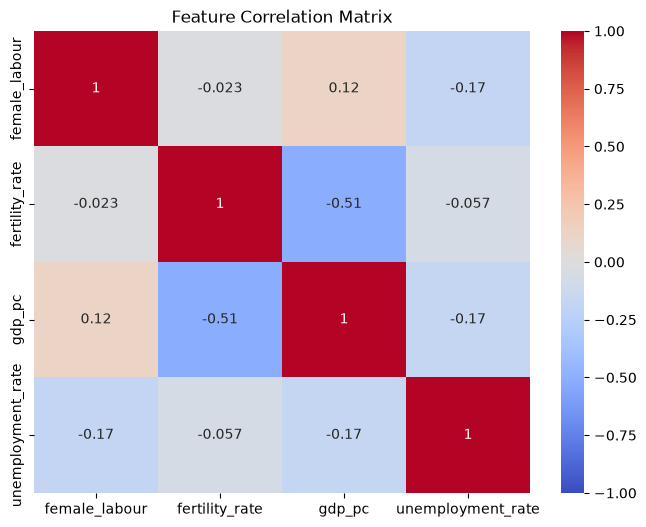

In [12]:
# Show the relation between gdp and fertility rate

corr_matrix = countries_df[num_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Feature Correlation Matrix')
plt.show()

# Perform a Cluster Analysis


## Pre-process the data

### *Scale the data* 
Scale the data using a scaler of your choice

In [13]:
# Drop any feature not required for clustering

X = countries_df.drop(columns='country')
X['gdp_pc'] = np.log(X['gdp_pc'])
X.head()

,female_labour,fertility_rate,gdp_pc,unemployment_rate
0,21.25,4.47,6.343582,11.06
1,42.19,1.62,8.396999,12.30
2,20.13,3.02,8.332869,11.89
3,50.20,5.52,8.187330,7.00
4,43.00,2.26,9.481314,9.22


In [14]:
# log transformer
countries_df

,country,female_labour,fertility_rate,gdp_pc,unemployment_rate
0,Afghanistan,21.25,4.47,568.83,11.06
1,Albania,42.19,1.62,4433.74,12.30
2,Algeria,20.13,3.02,4158.33,11.89
3,Angola,50.20,5.52,3595.11,7.00
4,Argentina,43.00,2.26,13112.40,9.22
...,...,...,...,...,...
174,Virgin Islands (U.S.),49.12,2.06,35740.02,7.99
175,West Bank and Gaza,19.85,3.64,3417.79,26.26
176,"Yemen, Rep.",7.90,3.79,1290.93,13.01
177,Zambia,48.30,4.63,1368.60,12.01


In [15]:
# Scale your features

scaler = RobustScaler().set_output(transform='pandas')
X_scaled = scaler.fit_transform(X)
X_scaled.head()

,female_labour,fertility_rate,gdp_pc,unemployment_rate
0,-2.690867,1.158442,-1.082286,1.010657
1,-0.238876,-0.322078,-0.113521,1.230906
2,-2.822014,0.405195,-0.143777,1.158082
3,0.699063,1.703896,-0.212439,0.289520
4,-0.144028,0.010390,0.398038,0.683837


## Run the algorithm and Evaluate the Results
 

In this analysis, we'll use inertia and the silhouette score to select the number of clusters *k* before running the final algorithm on our data.

### *Elbow method* 
- Plot the inertia scores for a range of *k* values in an elbow plot

In [16]:
# initialise list of ks and list to store the inertia scores
inertias = 
Ks = 

# iterate over the values of k
for i in Ks:
    
    # initialise a kmeans model with k clusters
    
    # fit the model to the scaled data
    
    # extract the inertia score and 
    # append the score to the list of scores


SyntaxError: invalid syntax (1716132350.py, line 2)

In [ ]:
# plot the inertias in an elbow plot to find the optimal k
??

# add labels to your plot
??


#### How many clusters to choose?

????

### *Silhouette score*


In [ ]:
# plot the silhouette scores for a range of ks in a bar plot 

# initialise list of ks and list to store silhouette scores
scores = ________
Ks = ________

# iterate over the values of k
for i in Ks:

    # initialise a kmeans model with k clusters
    ________
    
    # fit the model to the scaled data
    ________
    
    # Calcualte the silhouette score (where arguments = X, labels)
    ________
    
    # extract the silhouette score 
    # and append the score to the overall list of silhouette scores
    ________

In [ ]:
# plot the inertias in a bar plot to find the optimal k
??


# add labels to your plot
??


#### How many clusters to use?

????

### *Train your final model*

In [ ]:
# initialise a kmeans model with selected k
# ( use random_state=123 )

model_1  = ??

# fit the model to the scaled data
??

In [ ]:
# Show your labels

??

In [ ]:
# Add cluster labels as a new column in original dataframe

countries_df['cluster'] = ??

In [ ]:
# Check the dataframe

countries_df.head()

### *Inspect cluster centroids*

In [ ]:
# Inspect the resulting cluster centroids

??

In [ ]:
# We can store these values in a dataframe to look at them more easily
# Hint: don't forget to reverse transform your clusters dimensions

cluster_centroids_df = ??

# view the centroid for each cluster
cluster_centroids_df

#### How to interpret the results above?

###### Interpretation per cluster

????????            

###### Interpretation per feature

????????            


###### Overall insight: 

????????            

# Interpret the Results
## *Cluster membership*
- Display the number of countries in each cluster. 
- Display the names of the countries within each of the clusters.

In [ ]:
# Plot the number of countries per cluster

??

In [ ]:
# Display the names of the countries within each cluster

??

## *Draw a pair plot*

Using `pairplot()` from the `seaborn` library:
- Create a pair plot of the data, with the values coloured by cluster membership.
- *Hint:* To visualise the clusters easier, you might want to experiment around with the transparency of the scatter points using the argument `alpha` and the colour pallete using the argument `palette`.

In [ ]:
# Create a pair plot with points coloured by cluster membership 

??

### *Interpret the clusters*

Write a sentence that interprets the clusters above


????????

# Clustering with DBSCAN

Run DBSCAN on the same dataset and check whether you obtain the same number of clusters as K-Means.

**Note**: Manually perform a grid search by trying different combinations of `eps` and `min_samples` to find the best parameters. Remember that DBSCAN can also identify noise points (-1), which should not be counted as a cluster.